# Projet DVF : étape 5, perte robuste, prix des voisins, explication du modèle

**Constats des étapes 3 et 4**
- Le modèle sous-estime 2025 (biais médian d'environ −4 %), et les tentatives de correction par la tendance n'ont pas marché.
- Les ventes atypiques (biens à rénover, ventes familiales) ont des prix très bas. DVF ne dit rien de l'état du bien, donc le modèle ne peut pas les reconnaître.
- Le modèle ne connaît l'emplacement qu'au niveau de la **commune**.

**Trois idées testées**
1. **Perte robuste** : jusqu'ici, LightGBM minimisait l'erreur quadratique sur `log(prix)`, c'est-à-dire qu'il visait la **moyenne**. Les ventes atypiques tirent cette moyenne vers le bas. Avec la perte **L1**, il vise la **médiane**, qui les ignore. C'est aussi plus cohérent avec notre métrique principale, la MedAPE (une médiane).
2. **Prix des voisins** : prix moyen (en log) des ventes du même quartier (**section cadastrale**), de la même commune et du même type de bien. Les petits groupes sont « rétrécis » vers le niveau supérieur (lissage bayésien).
3. **Indice local** : niveau et tendance récents des prix calculés sur DVF lui-même, par zone (Pays de Gex ou non) et type de bien, avec 6 mois de délai de publication.

**Règles anti-fuite**
- Prix des voisins : codage **hors échantillon** (validation croisée en 5 blocs) sur les années d'entraînement. Pour l'année testée, on n'utilise que les années précédentes. Une vente ne voit donc jamais son propre prix, ni aucun prix de l'année testée.
- Indice local : seules les ventes antérieures à `date − 6 mois` sont utilisées.
- Choix sur le **backtest 2024** (entraînement ≤ 2023). Le **test 2025** n'est regardé qu'une fois. Référence = scénario A de l'étape 4.

**Pour la section cadastrale**, il faut relancer l'étape 1 après la petite modification indiquée dans `README_etape5.md`. Sans elle, ce notebook fonctionne quand même, sans le niveau section.

In [1]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt, warnings, os
import lightgbm as lgb
from sklearn.model_selection import KFold
warnings.filterwarnings('ignore')
pd.set_option('display.width', 220); pd.set_option('display.max_columns', 60)

SEED, SEEDS = 42, (0, 1, 2)
DATA = 'data'
K_SHRINK = 8     # force du lissage des prix des voisins (nombre de ventes « virtuelles » du niveau supérieur)
LAG_M = 6        # mois : délai de publication du DVF (indice local)
ALPHA = 0.20     # intervalles de prédiction à 80 %

## 1. Données
On repart des variables de l'étape 3. Si `dvf_clean.parquet` contient la colonne `section` (étape 1 modifiée), on la récupère.

In [2]:
df = pd.read_parquet(f'{DATA}/dvf_features_etape3.parquet')
df['date'] = pd.to_datetime(df['date'])
clean = pd.read_parquet(f'{DATA}/dvf_clean.parquet')

HAS_SECTION = 'section' in clean.columns
if HAS_SECTION:
    clean['date'] = pd.to_datetime(clean['date'])
    aligne = (len(clean) == len(df) and np.allclose(clean['prix_m2'].values, df['prix_m2'].values)
              and (clean['date'].values == df['date'].values).all())
    if aligne:
        df['section'] = clean['section'].values
    else:   # ordre différent : jointure sur une clé
        key = ['date', 'insee', 'valeur_fonciere', 'surface_bati', 'type_local']
        df = df.merge(clean.drop_duplicates(key)[key + ['section']], on=key, how='left')
    df['section'] = df['section'].fillna(df['insee'] + '_?')
    vc = df['section'].value_counts()
    print(f'sections cadastrales : {len(vc)} | ventes par section : médiane {vc.median():.0f}, '
          f'{(vc >= 5).sum()} sections avec au moins 5 ventes')
else:
    print('⚠ Pas de colonne « section » : le prix des voisins est calculé au niveau commune seulement.')

df = df.sort_values('date').reset_index(drop=True)
df['zone'] = np.where(df['pays_de_gex'] == 1, 'gex', 'ain')
print(df.shape)

sections cadastrales : 2440 | ventes par section : médiane 5, 1333 sections avec au moins 5 ventes
(30125, 41)


## 2. Prix des voisins (codage hors échantillon) et indice local
**Lissage hiérarchique** : `type → zone×type → commune → commune×type → section → section×type`. À chaque niveau, l'estimation vaut `(somme + K × parent) / (n + K)` : un groupe avec peu de ventes reste proche de son parent.

**Hors échantillon** : pour une année testée `Y`, les ventes avant `Y` sont codées en 5 blocs (chaque bloc est codé avec les 4 autres). Les ventes de `Y` sont codées avec **toutes** les ventes avant `Y`.

In [3]:
NIVEAUX = [('type', ['type_local']), ('zone_type', ['zone', 'type_local']),
           ('commune', ['insee']), ('commune_type', ['insee', 'type_local'])]
if HAS_SECTION:
    NIVEAUX += [('section', ['section']), ('section_type', ['section', 'type_local'])]

def coder(fit_idx, app_idx):
    """Prix des voisins pour les ventes app_idx, calculé uniquement avec les ventes fit_idx."""
    f, a = df.loc[fit_idx], df.loc[app_idx]
    est, res = None, {}
    for nom, keys in NIVEAUX:
        g = f.groupby(keys)['y'].agg(['sum', 'count'])
        m = a[keys].merge(g, left_on=keys, right_index=True, how='left')
        s, n = m['sum'].fillna(0).values, m['count'].fillna(0).values
        moy = np.where(n > 0, s / np.maximum(n, 1), np.nan)
        est = moy if est is None else np.where(np.isnan(est), moy, (s + K_SHRINK * est) / (n + K_SHRINK))
        res[f'vois_{nom}'], res[f'n_{nom}'] = est, n
    return pd.DataFrame(res, index=app_idx)

def voisins(year):
    tr, te = df.index[df.annee < year], df.index[df.annee == year]
    parts = [coder(tr, te)]
    for a, b in KFold(5, shuffle=True, random_state=SEED).split(tr):
        parts.append(coder(tr[a], tr[b]))
    return pd.concat(parts).reindex(df.index)

# indice local : moyenne de log(prix_m2) par zone × type sur les 6 et 24 derniers mois, avec 6 mois de délai
M = 30.44
T_DAYS = (df['date'] - pd.Timestamp('2022-01-01')).dt.days.values.astype(float)
def moyenne_passee(keys, win_m, n_min=30):
    g = df[keys].astype(str).agg('|'.join, axis=1).values
    out = np.full(len(df), np.nan); borne = T_DAYS - LAG_M * M
    for _, idx in pd.Series(np.arange(len(df))).groupby(g):
        idx = idx.values; t = T_DAYS[idx]; cs = np.concatenate([[0], np.cumsum(df['y'].values[idx])])
        hi = np.searchsorted(t, borne[idx]); lo = np.searchsorted(t, borne[idx] - win_m * M)
        n = hi - lo; out[idx] = np.where(n >= n_min, (cs[hi] - cs[lo]) / np.maximum(n, 1), np.nan)
    return out
df['idx_local_6m'] = moyenne_passee(['zone', 'type_local'], 6)
df['tend_local'] = df['idx_local_6m'] - moyenne_passee(['zone', 'type_local'], 24)

FE = {y: voisins(y) for y in (2024, 2025)}
VOIS = list(FE[2025].columns)
VOIS_COMMUNE = [c for c in VOIS if 'section' not in c]
INDICE = ['idx_local_6m', 'tend_local']
print('variables créées :', VOIS + INDICE)
display(pd.concat([df[['date', 'commune', 'type_local', 'prix_m2'] + INDICE], FE[2025]], axis=1)
        [df.annee == 2025].sample(5, random_state=1).round(3))

variables créées : ['vois_type', 'n_type', 'vois_zone_type', 'n_zone_type', 'vois_commune', 'n_commune', 'vois_commune_type', 'n_commune_type', 'vois_section', 'n_section', 'vois_section_type', 'n_section_type', 'idx_local_6m', 'tend_local']


,date,commune,type_local,prix_m2,idx_local_6m,tend_local,vois_type,n_type,vois_zone_type,n_zone_type,vois_commune,n_commune,vois_commune_type,n_commune_type,vois_section,n_section,vois_section_type,n_section_type
25109,2025-05-27,AMBERIEU-EN-BUGEY,Appartement,2500.000,7.602,-0.036,7.885,8161,7.632,5468,7.738,504.0,7.669,222.0,7.745,34.0,7.792,17.0
25859,2025-07-01,DOMPIERRE-SUR-VEYLE,Maison,2017.647,7.731,-0.008,7.819,14316,7.747,12932,7.795,29.0,7.786,28.0,7.829,6.0,7.806,5.0
24236,2025-04-09,ARBENT,Maison,2783.309,7.728,-0.018,7.819,14316,7.747,12932,7.459,61.0,7.518,41.0,7.541,7.0,7.581,6.0
29319,2025-12-08,DAGNEUX,Appartement,2142.857,7.642,0.014,7.885,8161,7.632,5468,7.953,146.0,7.962,54.0,7.912,30.0,7.888,20.0
25675,2025-06-25,MONTLUEL,Appartement,2023.529,7.608,-0.024,7.885,8161,7.632,5468,7.874,242.0,7.822,144.0,7.718,60.0,7.686,55.0


### Audit anti-fuite
- Pour les ventes de 2025, le prix des voisins au niveau commune × type doit être **exactement** la moyenne des ventes 2022-2024.
- Pour les ventes avant 2025, il ne doit **jamais** utiliser la vente elle-même : on le vérifie en recalculant à la main pour une vente.

In [4]:
i = df.index[df.annee == 2025][500]; r = df.loc[i]
passe = df[(df.annee < 2025) & (df.insee == r.insee) & (df.type_local == r.type_local)]
print(f'Vente du {r.date.date()} à {r.commune} ({r.type_local}) : {len(passe)} ventes 2022-2024 utilisées, '
      f'aucune de 2025 : {(passe.annee < 2025).all()}')
assert FE[2025].loc[i, 'n_commune_type'] == len(passe)
j = df.index[df.annee == 2023][100]
assert FE[2025].loc[j, 'n_commune_type'] < ((df.annee < 2025) & (df.insee == df.loc[j, 'insee'])
                                             & (df.type_local == df.loc[j, 'type_local'])).sum()
print('✓ audit réussi')

Vente du 2025-02-03 à SAINT-ANDRE-DE-CORCY (Maison) : 58 ventes 2022-2024 utilisées, aucune de 2025 : True
✓ audit réussi


## 3. Moteur d'évaluation (même protocole que l'étape 4)

In [5]:
BASE_NUM = ['surface_bati','log_surface','pieces','surface_terrain','log_terrain','nb_dependances',
            'a_dependance','surface_carrez','carrez_dispo','mois','mois_sin','mois_cos']
GEO = ['lat','lon','dist_geneve_km','dist_lyon_km','dist_bourg_km']
PROFIL = ['population','log_population'] + [c for c in df.columns if c.startswith('fil_')]
CAT = ['type_local','commune']
REF_FEATS = BASE_NUM + GEO + PROFIL                     # = scénario A de l'étape 4

LGB_PARAMS = dict(objective='regression', learning_rate=0.03, num_leaves=31, min_child_samples=20,
                  subsample=0.8, subsample_freq=1, colsample_bytree=0.8, reg_lambda=1.0,
                  cat_smooth=20, cat_l2=10, min_data_per_group=10, verbose=-1)

def metrics(y_true, y_pred):
    e = y_pred - y_true; ape = np.abs(e) / y_true
    return {'MedAPE %': np.median(ape)*100, 'MAPE %': ape.mean()*100, '±10 %': (ape <= .1).mean()*100,
            '±20 %': (ape <= .2).mean()*100, 'MAE': np.abs(e).mean(), 'biais médian %': np.median(e / y_true)*100}

def X_of(d, feats, cats):
    X = d[feats + CAT].copy()
    for c in CAT: X[c] = pd.Categorical(X[c], categories=cats[c])
    return X

def predire_annee(year, sc):
    """Entraîne sur les ventes < year, prédit l'année `year`. Renvoie prédictions €/m², modèles, catégories."""
    feats, params = sc['feats'], {**LGB_PARAMS, **sc.get('params', {})}
    D = pd.concat([df, FE[year]], axis=1)
    tr, te = D[D.annee < year], D[D.annee == year]
    cats = {c: tr[c].astype('category').cat.categories for c in CAT}
    a, b = tr[tr.annee < year - 1], tr[tr.annee == year - 1]          # arrêt anticipé sur la dernière année du passé
    es = lgb.LGBMRegressor(n_estimators=5000, random_state=SEED, **params)
    es.fit(X_of(a, feats, cats), a['y'], eval_set=[(X_of(b, feats, cats), b['y'])],
           callbacks=[lgb.early_stopping(100, verbose=False)])
    n_trees = max(int(es.best_iteration_), 50)
    models = [lgb.LGBMRegressor(n_estimators=n_trees, random_state=s, **params)
              .fit(X_of(tr, feats, cats), tr['y']) for s in SEEDS]
    lp = np.mean([m.predict(X_of(te, feats, cats)) for m in models], axis=0)
    return np.exp(lp), models, cats

## 4. Scénarios
| scénario | perte | variables |
|---|---|---|
| A | quadratique (moyenne) | référence de l'étape 4 |
| B | **L1 (médiane)** | référence |
| C | Huber (compromis) | référence |
| D | L1 | + prix des voisins (commune) |
| E | L1 | + prix des voisins (jusqu'à la section), si disponible |
| F | L1 | + indice local |

In [6]:
L1, HUBER = dict(objective='regression_l1'), dict(objective='huber', alpha=0.15)
SC = {'A · référence (étape 4)':           dict(feats=REF_FEATS),
      'B · perte L1 (médiane)':            dict(feats=REF_FEATS, params=L1),
      'C · perte Huber':                   dict(feats=REF_FEATS, params=HUBER),
      'D · L1 + voisins commune':          dict(feats=REF_FEATS + VOIS_COMMUNE, params=L1)}
if HAS_SECTION:
    SC['E · L1 + voisins section'] = dict(feats=REF_FEATS + VOIS, params=L1)
SC['F · L1 + indice local'] = dict(feats=REF_FEATS + INDICE, params=L1)

P = {}
for name, sc in SC.items():
    for year in (2024, 2025):
        P[(name, year)] = predire_annee(year, sc)[0]
    print(f'{name:32s} fait')

A · référence (étape 4)          fait
B · perte L1 (médiane)           fait
C · perte Huber                  fait
D · L1 + voisins commune         fait
E · L1 + voisins section         fait
F · L1 + indice local            fait


## 5. Résultats
- **2024 (backtest)** sert à choisir. **2025 (test)** est la mesure finale.
- `Δ MedAPE` : écart avec A en points de % (négatif = mieux), intervalle de confiance bootstrap apparié à 95 % (✓ = exclut 0).

In [7]:
y24 = df.loc[df.annee == 2024, 'prix_m2'].values
y25 = df.loc[df.annee == 2025, 'prix_m2'].values
gex25 = df.loc[df.annee == 2025, 'pays_de_gex'].values == 1
ref = 'A · référence (étape 4)'

def delta_ci(p_ref, p_new, t, n=500):
    a, b = np.abs(p_ref - t) / t, np.abs(p_new - t) / t
    rng = np.random.default_rng(SEED); d = []
    for _ in range(n):
        i = rng.integers(0, len(t), len(t)); d.append(np.median(b[i]) - np.median(a[i]))
    return np.percentile(np.array(d) * 100, [2.5, 97.5])

rows = []
for name in SC:
    m24, m25, p = metrics(y24, P[(name, 2024)]), metrics(y25, P[(name, 2025)]), P[(name, 2025)]
    lo, hi = delta_ci(P[(ref, 2025)], p, y25) if name != ref else (0, 0)
    rows.append({'scénario': name, 'MedAPE 2024 (choix)': m24['MedAPE %'], 'biais 2024': m24['biais médian %'],
                 'MedAPE 2025 (test)': m25['MedAPE %'],
                 'Δ MedAPE': m25['MedAPE %'] - metrics(y25, P[(ref, 2025)])['MedAPE %'],
                 'IC95 Δ': f'[{lo:+.2f} ; {hi:+.2f}]', 'sig.': '✓' if (lo > 0 or hi < 0) else '',
                 'MAPE %': m25['MAPE %'], '±10 %': m25['±10 %'], '±20 %': m25['±20 %'], 'MAE': m25['MAE'],
                 'biais 2025': m25['biais médian %'],
                 'biais Gex': np.median((p[gex25] - y25[gex25]) / y25[gex25]) * 100,
                 'biais hors Gex': np.median((p[~gex25] - y25[~gex25]) / y25[~gex25]) * 100})
RES = pd.DataFrame(rows).set_index('scénario')
display(RES.round(2))

CHOIX = RES['MedAPE 2024 (choix)'].idxmin()
print('\nScénario retenu (meilleur sur le backtest 2024) :', CHOIX)

,MedAPE 2024 (choix),biais 2024,MedAPE 2025 (test),Δ MedAPE,IC95 Δ,sig.,MAPE %,±10 %,±20 %,MAE,biais 2025,biais Gex,biais hors Gex
scénario,,,,,,,,,,,,,
A · référence (étape 4),16.57,-0.93,16.12,0.00,[+0.00 ; +0.00],,24.01,31.56,59.95,565.02,-4.21,-8.68,-2.92
B · perte L1 (médiane),16.02,2.79,15.11,-1.02,[-1.31 ; -0.73],✓,24.52,34.82,62.13,547.66,-0.51,-5.25,0.74
C · perte Huber,16.09,2.35,15.14,-0.98,[-1.24 ; -0.67],✓,24.35,34.58,61.90,546.86,-1.07,-5.52,0.24
D · L1 + voisins commune,16.38,3.21,15.34,-0.78,[-1.07 ; -0.47],✓,24.77,34.47,61.57,552.96,-0.34,-5.60,1.48
E · L1 + voisins section,15.68,3.05,15.09,-1.03,[-1.35 ; -0.66],✓,24.50,34.82,61.98,548.06,-0.62,-5.94,1.00
F · L1 + indice local,16.26,2.82,15.17,-0.95,[-1.23 ; -0.63],✓,24.40,34.58,62.12,544.07,-0.91,-2.50,-0.34



Scénario retenu (meilleur sur le backtest 2024) : E · L1 + voisins section


### Pourquoi la perte L1 aide : le biais par tranche de prix
La perte quadratique est tirée vers le bas par les ventes atypiques très bon marché, donc elle sous-estime les biens « normaux ». La perte L1 les ignore.
Contrepartie à mentionner : la MAPE (moyenne des erreurs) peut augmenter, car les ventes atypiques restent très mal prédites.

In [8]:
t25 = df[df.annee == 2025].copy()
t25['tranche_prix'] = pd.cut(t25.prix_m2, [0, 1000, 1500, 2000, 3000, 4000, 12000])
for k in (ref, CHOIX):
    t25['b_' + k[0]] = (P[(k, 2025)] - t25.prix_m2) / t25.prix_m2 * 100
    t25['e_' + k[0]] = np.abs(P[(k, 2025)] - t25.prix_m2) / t25.prix_m2 * 100
g = t25.groupby('tranche_prix', observed=True)
display(pd.DataFrame({'n': g.size(), f'MedAPE {ref[0]}': g['e_' + ref[0]].median(), f'MedAPE {CHOIX[0]}': g['e_' + CHOIX[0]].median(),
                      f'biais {ref[0]}': g['b_' + ref[0]].median(), f'biais {CHOIX[0]}': g['b_' + CHOIX[0]].median()}).round(1))

,n,MedAPE A,MedAPE E,biais A,biais E
tranche_prix,,,,,
"(0, 1000]",252,98.9,113.5,98.9,113.5
"(1000, 1500]",753,36.6,41.6,36.6,41.6
"(1500, 2000]",1199,15.1,16.2,8.2,11.7
"(2000, 3000]",2696,14.1,12.8,-6.7,-2.3
"(3000, 4000]",1321,15.5,13.5,-11.2,-6.7
"(4000, 12000]",1427,14.5,12.4,-13.8,-10.9


## 6. Modèle final : détail des erreurs 2025

In [9]:
FINAL = CHOIX
SC_F = SC[FINAL]
p25, models_F, cats_F = predire_annee(2025, SC_F)
t25 = pd.concat([df, FE[2025]], axis=1)[df.annee == 2025].copy()
t25['pred'], t25['pred_A'] = p25, P[(ref, 2025)]
t25['ape'] = np.abs(t25.pred - t25.prix_m2) / t25.prix_m2 * 100
t25['ape_A'] = np.abs(t25.pred_A - t25.prix_m2) / t25.prix_m2 * 100
t25['biais'] = (t25.pred - t25.prix_m2) / t25.prix_m2 * 100
for col in ['type_local', 'pays_de_gex']:
    g = t25.groupby(col, observed=True)
    print(f'--- par {col}')
    display(pd.DataFrame({'n': g.size(), 'MedAPE A': g['ape_A'].median(),
                          'MedAPE final': g['ape'].median(), 'biais final': g['biais'].median()}).round(1))

--- par type_local


,n,MedAPE A,MedAPE final,biais final
type_local,,,,
Appartement,2768,15.5,14.1,-4.6
Maison,4880,16.6,15.7,1.5


--- par pays_de_gex


,n,MedAPE A,MedAPE final,biais final
pays_de_gex,,,,
0,6306,16.8,16.0,1.0
1,1342,13.7,11.8,-5.9


### Carte des erreurs par commune (test 2025)
Chaque point est une commune avec au moins 10 ventes en 2025. Couleur = biais médian (rouge : le modèle surestime, bleu : il sous-estime) ; taille = nombre de ventes.

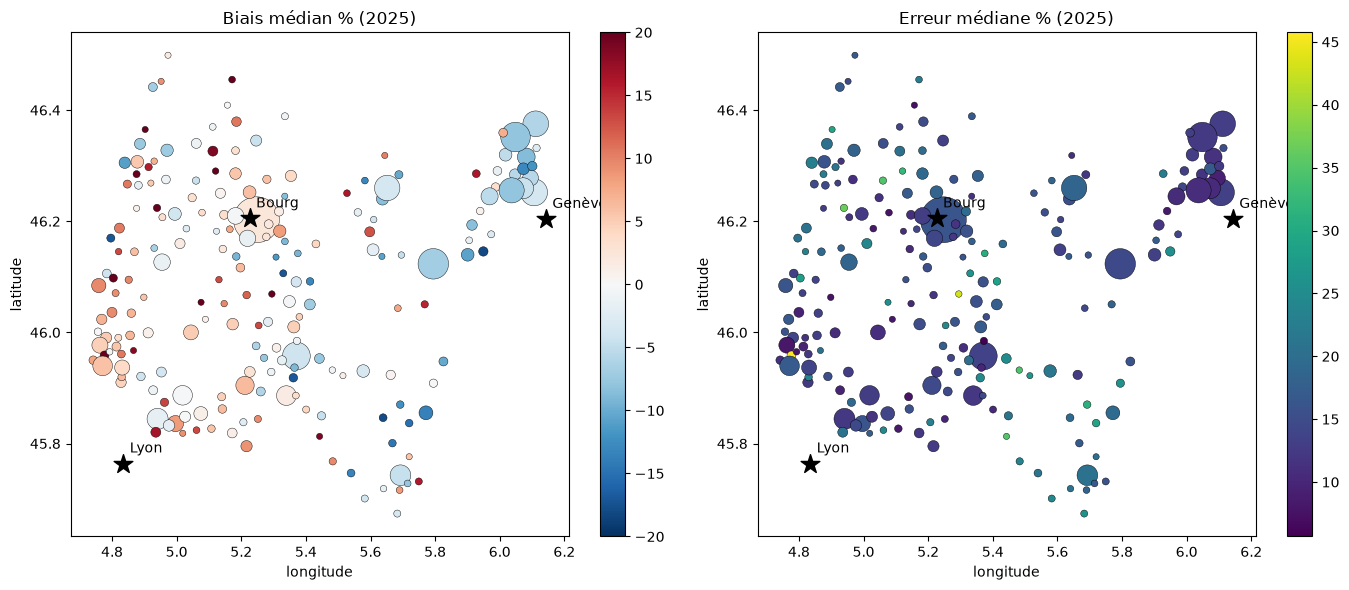

,lon,lat,n,medape,biais
commune,,,,,
SAINT-DIDIER-DE-FORMANS,4.8,46.0,20,45.8,45.8
DRUILLAT,5.3,46.1,11,43.1,20.8
BIZIAT,4.9,46.2,14,36.6,36.6
SERRIERES-DE-BRIORD,5.4,45.8,10,35.0,19.0
CONFRANCON,5.1,46.3,14,34.8,-4.4
ARGIS,5.5,45.9,11,34.4,-0.7
SAINT-MARTIN-LE-CHATEL,5.1,46.3,11,32.3,32.3
ARTEMARE,5.7,45.9,15,31.2,-12.2


In [10]:
gc = t25.groupby('commune').agg(lon=('lon', 'first'), lat=('lat', 'first'), n=('ape', 'size'),
                                medape=('ape', 'median'), biais=('biais', 'median'))
gc = gc[gc.n >= 10].dropna()
fig, ax = plt.subplots(1, 2, figsize=(14, 6))
for k, (col, cmap, titre, lim) in enumerate([('biais', 'RdBu_r', 'Biais médian % (2025)', 20),
                                              ('medape', 'viridis', 'Erreur médiane % (2025)', None)]):
    sc = ax[k].scatter(gc.lon, gc.lat, c=gc[col], s=gc.n * 2, cmap=cmap,
                       vmin=-lim if lim else None, vmax=lim, edgecolor='k', lw=.3)
    plt.colorbar(sc, ax=ax[k]); ax[k].set_title(titre); ax[k].set_xlabel('longitude'); ax[k].set_ylabel('latitude')
    for nom, (lo_, la_) in {'Genève': (6.143, 46.204), 'Lyon': (4.835, 45.764), 'Bourg': (5.226, 46.205)}.items():
        ax[k].scatter([lo_], [la_], marker='*', s=200, c='k'); ax[k].annotate(nom, (lo_ + .02, la_ + .02))
plt.tight_layout(); plt.show()
display(gc.sort_values('medape', ascending=False).head(8).round(1))

## 7. Explication du modèle (SHAP)
SHAP répond à la question : « pour cette vente, de combien chaque variable a-t-elle poussé le prix prédit vers le haut ou vers le bas ? ».
- **Barres** : importance moyenne de chaque variable.
- **Nuage de points** : sens de l'effet (rouge = valeur élevée de la variable ; à droite = fait monter le prix).
- **Tableau** : part de l'effet total par groupe de variables.

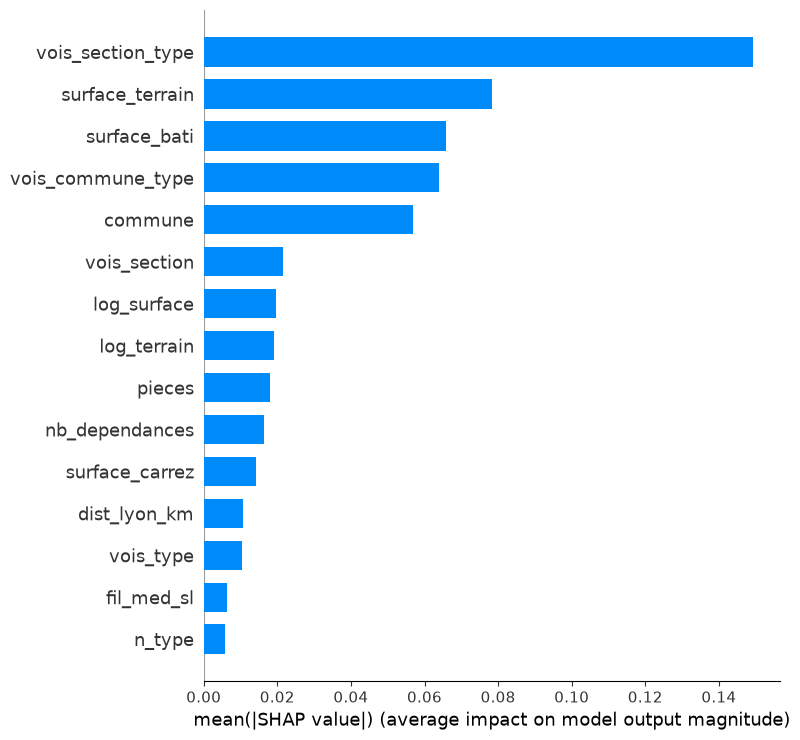

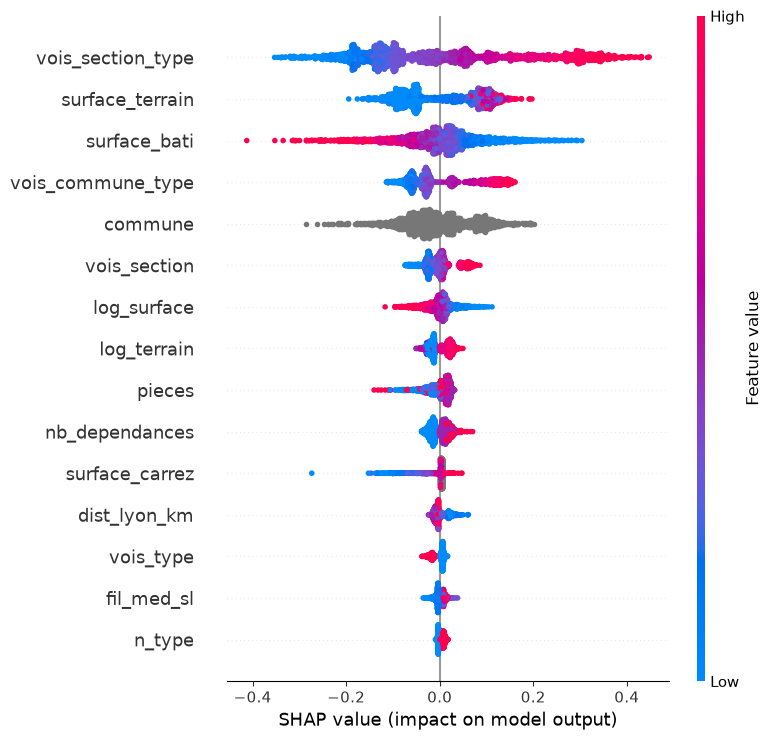

,% de l'effet total
prix des voisins,44.3
bien,40.1
emplacement,13.2
profil commune,2.4


In [11]:
import shap
Xs = X_of(t25.sample(2000, random_state=SEED), SC_F['feats'], cats_F)
sv = shap.TreeExplainer(models_F[0]).shap_values(Xs)
shap.summary_plot(sv, Xs, plot_type='bar', max_display=15, show=False); plt.tight_layout(); plt.show()
shap.summary_plot(sv, Xs, max_display=15, show=False); plt.tight_layout(); plt.show()

GROUPES = {**{f: 'bien' for f in BASE_NUM}, 'type_local': 'bien',
           **{f: 'emplacement' for f in GEO}, 'commune': 'emplacement',
           **{f: 'profil commune' for f in PROFIL},
           **{f: 'prix des voisins' for f in VOIS}, **{f: 'indice local' for f in INDICE}}
imp = pd.Series(np.abs(sv).mean(axis=0), index=Xs.columns)
display((imp.groupby(lambda f: GROUPES.get(f, 'autre')).sum() / imp.sum() * 100)
        .sort_values(ascending=False).round(1).to_frame("% de l'effet total"))

## 8. Intervalles de prédiction à 80 % (Mondrian, calibrés sur le backtest 2024)

In [12]:
d24 = df[df.annee == 2024]
r24 = np.abs(d24['y'].values - np.log(P[(FINAL, 2024)]))
def qconf(r):
    n = len(r); return np.quantile(r, min(1, np.ceil((n + 1) * (1 - ALPHA)) / n))
g24 = (d24['type_local'] + '_' + d24['pays_de_gex'].astype(str)).values
g25 = (t25['type_local'] + '_' + t25['pays_de_gex'].astype(str)).values
Q_GLOB = qconf(r24)
Q_GRP = {g: (qconf(r24[g24 == g]) if (g24 == g).sum() >= 30 else Q_GLOB) for g in np.unique(g24)}
qt = np.array([Q_GRP.get(g, Q_GLOB) for g in g25])
t25['lo80'], t25['hi80'] = t25.pred * np.exp(-qt), t25.pred * np.exp(qt)
ok = (t25.prix_m2 >= t25.lo80) & (t25.prix_m2 <= t25.hi80)
print(f'Couverture 2025 : {ok.mean()*100:.1f} % (objectif 80 %) | largeur relative médiane : '
      f'{np.median((t25.hi80 - t25.lo80) / t25.pred)*100:.1f} %')
display(t25.assign(ok=ok).groupby(['type_local', 'pays_de_gex'])['ok'].mean().mul(100).round(1).to_frame('couverture %'))

Couverture 2025 : 82.3 % (objectif 80 %) | largeur relative médiane : 80.0 %


couverture %
type_local  pays_de_gex              
Appartement 0                    82.1
            1                    82.6
Maison      0                    82.2
            1                    82.2

## 9. Utiliser le modèle : `predire()`
Estime un bien avec le modèle final, entraîné sur 2022-2024 (le même que celui évalué sur 2025). Renvoie le prix au m², le prix total et l'intervalle à 80 %.

In [13]:
COM = df.groupby('commune').first()
REF_VOIS = df[df.annee < 2025]

def predire(commune, type_local, surface, pieces, terrain=0, nb_dependances=0, date='2025-10-01', section=None):
    commune = commune.upper()
    if commune not in COM.index:
        raise ValueError(f'commune inconnue : {commune}')
    c, date = COM.loc[commune], pd.Timestamp(date)
    row = {'date': date, 'annee': date.year, 'mois': date.month, 'insee': c.insee, 'commune': commune,
           'type_local': type_local, 'surface_bati': surface, 'log_surface': np.log(surface), 'pieces': pieces,
           'surface_terrain': terrain, 'log_terrain': np.log1p(terrain), 'nb_dependances': nb_dependances,
           'a_dependance': int(nb_dependances > 0), 'surface_carrez': np.nan, 'carrez_dispo': 0,
           'mois_sin': np.sin(2*np.pi*date.month/12), 'mois_cos': np.cos(2*np.pi*date.month/12),
           'zone': c.zone, 'pays_de_gex': c.pays_de_gex, 'section': section}
    for f in GEO + PROFIL: row[f] = c[f]
    est = None                                     # prix des voisins : même calcul que coder()
    for nom, keys in NIVEAUX:
        sel = REF_VOIS
        for k in keys: sel = sel[sel[k] == row[k]]
        n, s = len(sel), sel['y'].sum()
        est = (s / n if n else np.nan) if est is None else (est if n == 0 else (s + K_SHRINK * est) / (n + K_SHRINK))
        row[f'vois_{nom}'], row[f'n_{nom}'] = est, n
    passe = df[(df.zone == c.zone) & (df.type_local == type_local) & (df.date < date - pd.Timedelta(days=LAG_M * M))]
    borne = date - pd.Timedelta(days=LAG_M * M)
    l6, l24 = passe[passe.date >= borne - pd.Timedelta(days=6 * M)], passe[passe.date >= borne - pd.Timedelta(days=24 * M)]
    row['idx_local_6m'] = l6.y.mean() if len(l6) >= 30 else np.nan
    row['tend_local'] = row['idx_local_6m'] - (l24.y.mean() if len(l24) >= 30 else np.nan)
    X = X_of(pd.DataFrame([row]), SC_F['feats'], cats_F)
    pm2 = float(np.exp(np.mean([m.predict(X) for m in models_F])))
    q = Q_GRP.get(f'{type_local}_{c.pays_de_gex}', Q_GLOB)
    return {'prix_m2': round(pm2), 'prix_total': int(round(pm2 * surface, -3)),
            'intervalle_80%': (int(round(pm2 * surface * np.exp(-q), -3)), int(round(pm2 * surface * np.exp(q), -3)))}

print(predire('BOURG-EN-BRESSE', 'Appartement', surface=65, pieces=3))
print(predire('GEX', 'Maison', surface=120, pieces=5, terrain=600, nb_dependances=1))
print(predire('OYONNAX', 'Maison', surface=90, pieces=4, terrain=400))

{'prix_m2': 1762, 'prix_total': 115000, 'intervalle_80%': (82000, 160000)}
{'prix_m2': 5418, 'prix_total': 650000, 'intervalle_80%': (510000, 830000)}
{'prix_m2': 2127, 'prix_total': 191000, 'intervalle_80%': (130000, 283000)}


## 10. Récapitulatif de tout le projet (test 2025)

,MedAPE %,MAPE %,±20 %,MAE
Étape 2 · baseline médiane commune×type,17.89,28.80,55.36,628.37
Étape 2 · LightGBM (bien + commune),16.26,24.27,59.61,569.73
Étape 3 · LightGBM + données externes,16.08,24.00,59.88,564.23
Étape 4 · scénario retenu (tendance zone),16.62,23.65,58.98,568.43
Étape 5 · E · L1 + voisins section,15.09,24.50,61.98,548.06


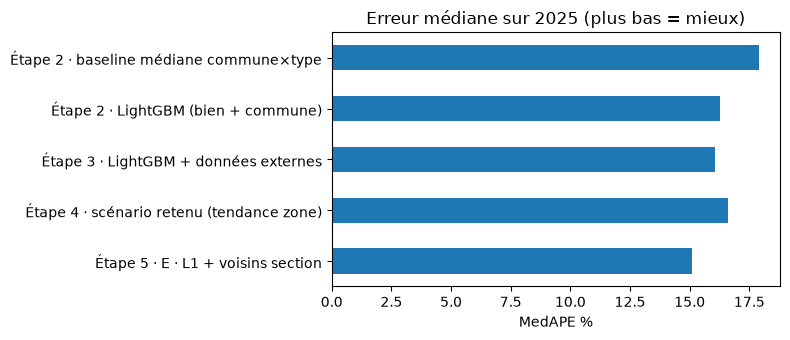

In [14]:
recap = []
if os.path.exists(f'{DATA}/etape2_metriques.csv'):
    e2 = pd.read_csv(f'{DATA}/etape2_metriques.csv', index_col=0)
    recap.append(('Étape 2 · baseline médiane commune×type', e2.loc['B1 médiane commune×type']))
    recap.append(('Étape 2 · LightGBM (bien + commune)', e2.loc['LightGBM']))
if os.path.exists(f'{DATA}/etape3_metriques.csv'):
    recap.append(('Étape 3 · LightGBM + données externes',
                  pd.read_csv(f'{DATA}/etape3_metriques.csv', index_col=0).loc['LightGBM']))
if os.path.exists(f'{DATA}/etape4_scenarios.csv'):
    e4 = pd.read_csv(f'{DATA}/etape4_scenarios.csv', index_col=0)
    recap.append(('Étape 4 · scénario retenu (tendance zone)',
                  e4.loc[e4['MedAPE 2024 (choix)'].idxmin()].rename({'MedAPE 2025 (test)': 'MedAPE %'})))
recap.append((f'Étape 5 · {FINAL}', pd.Series(metrics(y25, P[(FINAL, 2025)]))))
REC = pd.DataFrame({k: v for k, v in recap}).T[['MedAPE %', 'MAPE %', '±20 %', 'MAE']].astype(float)
display(REC.round(2))
REC['MedAPE %'].plot.barh(figsize=(8, 3.5), title='Erreur médiane sur 2025 (plus bas = mieux)')
plt.gca().invert_yaxis(); plt.xlabel('MedAPE %'); plt.tight_layout(); plt.show()

## 11. Sauvegarde

In [15]:
RES.to_csv(f'{DATA}/etape5_scenarios.csv')
REC.to_csv(f'{DATA}/etape5_recapitulatif.csv')
t25[['date', 'commune', 'type_local', 'pays_de_gex', 'surface_bati', 'prix_m2', 'pred_A', 'pred', 'lo80', 'hi80']] \
    .to_csv(f'{DATA}/etape5_predictions_test.csv', index=False)
print('Sauvegardé : etape5_scenarios.csv, etape5_recapitulatif.csv, etape5_predictions_test.csv')

Sauvegardé : etape5_scenarios.csv, etape5_recapitulatif.csv, etape5_predictions_test.csv


## À retenir pour le rapport
1. **Perte robuste** : passer de la perte quadratique à la perte L1 change la cible (médiane au lieu de moyenne). C'est cohérent avec la MedAPE et ça réduit le biais de 2025. Contrepartie : la MAPE peut augmenter.
2. **Prix des voisins** : au niveau commune, il n'apporte rien, car le modèle connaît déjà la commune. Le niveau section teste si l'emplacement **dans** la commune aide. Lire l'intervalle de confiance.
3. **Indice local** : comparer à l'indice régional de l'étape 3. S'il n'aide pas non plus, la conclusion est que la dérive 2025 n'était pas prévisible avec les données du passé.
4. **SHAP** et **carte des erreurs** : quelles variables comptent, et où le modèle se trompe.
5. **Limites** : la section cadastrale est un découpage administratif, pas un vrai quartier ; les ventes atypiques (bien à rénover, vente familiale) restent mal prédites car DVF ne décrit pas l'état du bien.